In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# 09 - Governance, tax compliance and public procurement
Proxies for administrative quality and for 'bad spending'. Governance scores are perception-based; the VAT gap is an estimate; procurement competition comes from the Single Market Scoreboard (2021-2024).

VAT gap Italy: {2013: 27.6, 2019: 19.3, 2023: 15.0} | median of others: {2013: 15.3, 2019: 10.4, 2023: 8.0} | rank 2023: (5, 26)


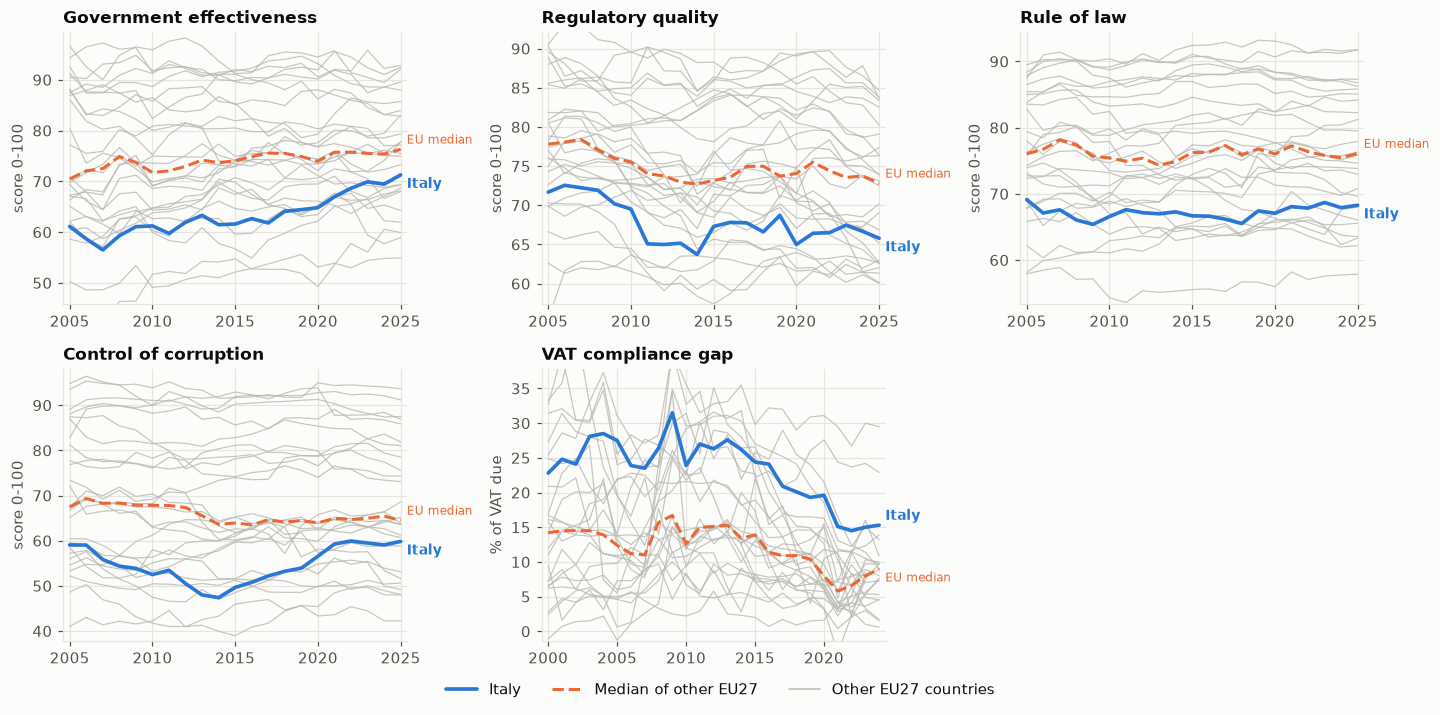

In [2]:
small_multiples(panel, [
    ("wgi_government_effectiveness", "Government effectiveness", "score 0-100"),
    ("wgi_regulatory_quality", "Regulatory quality", "score 0-100"),
    ("wgi_rule_of_law", "Rule of law", "score 0-100"),
    ("wgi_control_of_corruption", "Control of corruption", "score 0-100"),
    ("vat_compliance_gap_pct", "VAT compliance gap", "% of VAT due"),
], ncols=3, name="09_governance_overview")
w = wide(panel, "vat_compliance_gap_pct"); print("VAT gap Italy:", w[ITALY].loc[[2013, 2019, 2023]].round(1).to_dict(), "| median of others:", eu_median_ex_italy(w).loc[[2013, 2019, 2023]].round(1).to_dict(), "| rank 2023:", italy_rank(w, 2023))

corr(VAT gap, corruption control): -0.35 | corr(gov. effectiveness, income level): 0.8


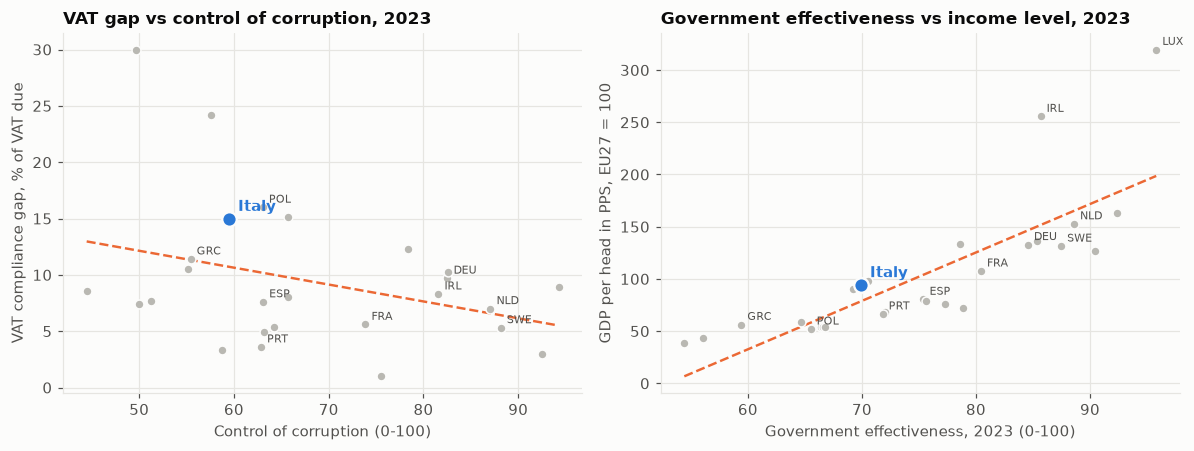

In [3]:
# Do cleaner/more effective governments collect more of the VAT due? (2023; EU27, Luxembourg excluded as unreliable in the source)
x = wide(panel, "wgi_control_of_corruption", EU27_ISO3).loc[2023]; y = wide(panel, "vat_compliance_gap_pct", EU27_ISO3).loc[2023]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
scatter_italy(axes[0], x, y, "Control of corruption (0-100)", "VAT compliance gap, % of VAT due", "VAT gap vs control of corruption, 2023")
ge = wide(panel, "wgi_government_effectiveness", EU27_ISO3).loc[2023]; inc = wide(panel, "gdp_pps_pc_eu27", EU27_ISO3).loc[2023]
scatter_italy(axes[1], ge, inc, "Government effectiveness, 2023 (0-100)", "GDP per head in PPS, EU27 = 100", "Government effectiveness vs income level, 2023")
fig.tight_layout(); save(fig, "09_governance_scatter")
print("corr(VAT gap, corruption control):", round(x.corr(y), 2), "| corr(gov. effectiveness, income level):", round(ge.corr(inc), 2))

proc_single_bidder_pct | Italy 2024: 34.0 | median of others: 27.0 | rank (1 = highest): 10/26
proc_direct_awards_pct | Italy 2024: 3.0 | median of others: 5.0 | rank (1 = highest): 20/26
proc_decision_speed_days | Italy 2024: 123.0 | median of others: 74.0 | rank (1 = highest): 4/27


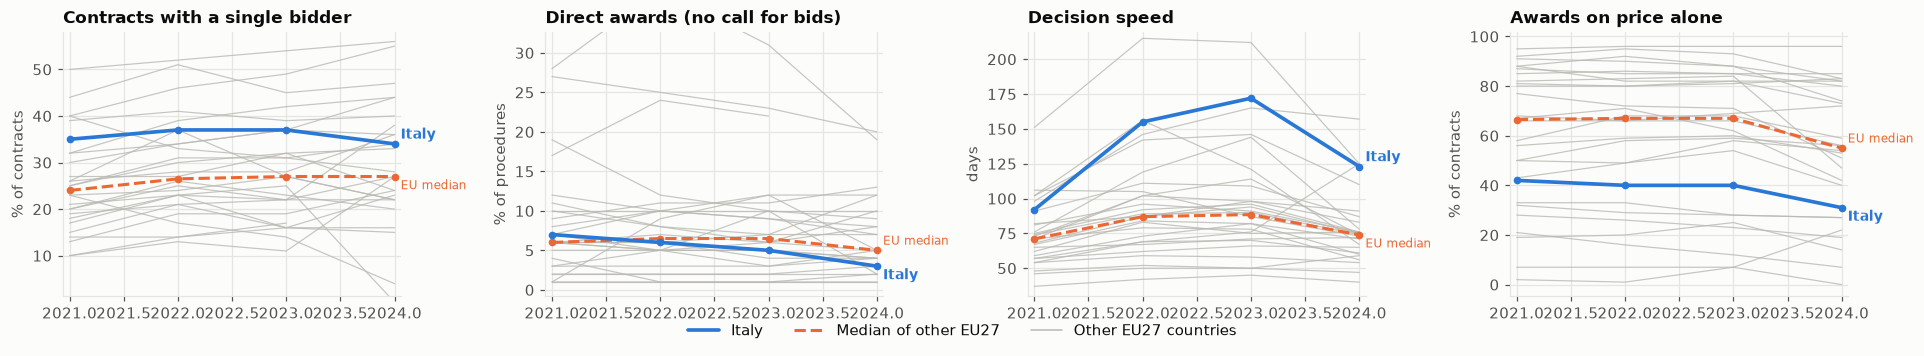

In [4]:
# Public procurement competition (Single Market Scoreboard, from TED; 2021-2024)
items = [
    (wide(panel, "proc_single_bidder_pct"), "Contracts with a single bidder", "% of contracts"),
    (wide(panel, "proc_direct_awards_pct"), "Direct awards (no call for bids)", "% of procedures"),
    (wide(panel, "proc_decision_speed_days"), "Decision speed", "days"),
    (wide(panel, "proc_price_only_award_pct"), "Awards on price alone", "% of contracts"),
]
small_multiples_wide(items, ncols=4, name="09_procurement")
for ind in ["proc_single_bidder_pct", "proc_direct_awards_pct", "proc_decision_speed_days"]:
    w = wide(panel, ind)
    print(ind, "| Italy 2024:", round(w.loc[2024, ITALY], 1), "| median of others:", round(eu_median_ex_italy(w).loc[2024], 1), "| rank (1 = highest): %d/%d" % italy_rank(w, 2024))

year,2018,2019,2020,2021,2022
tax,,,,,
ACCISE sui prodotti energetici (benzina e gasolio),1498.0,1914.0,1722.0,1753.0,712.0
Addizionali locali IRPEF (lavoro dipendente),801.0,804.0,691.0,680.0,733.0
CANONE RAI,239.0,241.0,248.0,225.0,209.0
IMU-TASI,5377.0,5381.0,5110.0,4976.0,4925.0
IRAP,5354.0,5040.0,4492.0,4920.0,3617.0
IRES,8723.0,9171.0,8205.0,7607.0,10320.0
IRPEF lavoro autonomo e impresa,35941.0,35064.0,33620.0,35333.0,36952.0
IRPEF lavoro dipendente (irregolare),4532.0,4675.0,3882.0,3997.0,3606.0
IVA,32137.0,31071.0,26647.0,27945.0,28966.0


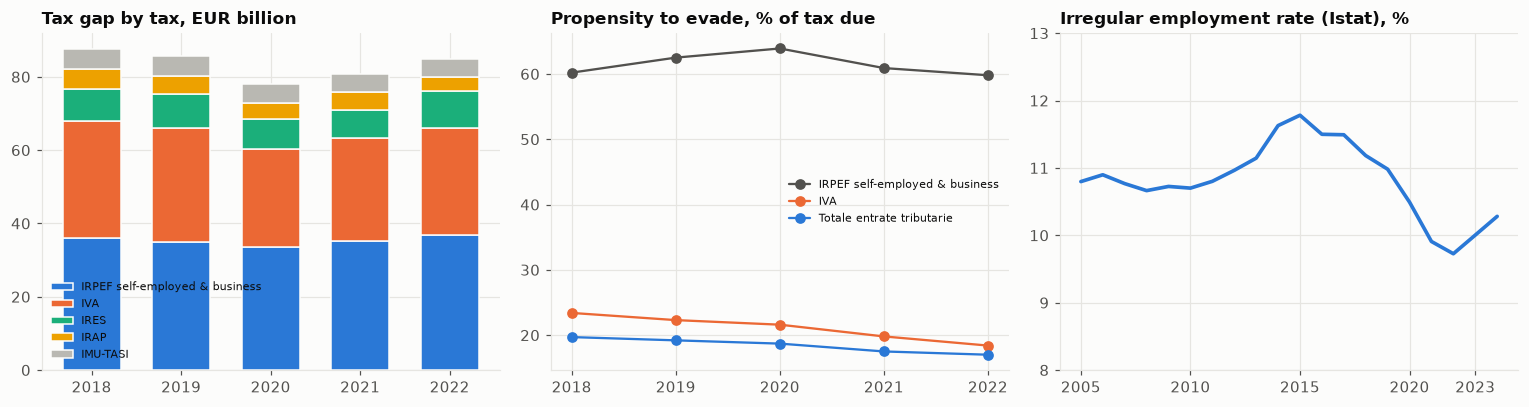

In [5]:
# Italy only: the Ministry of Economy's tax-gap estimates (2018-2022) and Istat's irregular-work rate
mef = pd.read_parquet(PROCESSED / "italy_tax_gap_mef.parquet"); irr = pd.read_parquet(PROCESSED / "istat_irregular_work.parquet")
gap = mef[(mef.measure == "gap_meur") & mef.tax.isin(["IRPEF lavoro autonomo e impresa", "IVA", "IRES", "IRAP", "IMU-TASI"])].pivot(index="year", columns="tax", values="value") / 1000
prop = mef[(mef.measure == "propensity_pct") & mef.tax.isin(["Totale entrate tributarie", "IVA", "IRPEF lavoro autonomo e impresa"])].pivot(index="year", columns="tax", values="value")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
bottom = np.zeros(len(gap))
for col, colr in zip(["IRPEF lavoro autonomo e impresa", "IVA", "IRES", "IRAP", "IMU-TASI"], [ITALY_C, EU_C, "#1baf7a", "#eda100", PEER_C], strict=True):
    axes[0].bar(gap.index, gap[col], bottom=bottom, color=colr, label=col.replace("lavoro autonomo e impresa", "self-employed & business"), width=0.65, edgecolor=SURFACE); bottom += gap[col].values
axes[0].set_title("Tax gap by tax, EUR billion"); axes[0].legend(fontsize=7, loc="lower left")
for col, colr in zip(prop.columns, [INK2, EU_C, ITALY_C], strict=True): axes[1].plot(prop.index, prop[col], marker="o", color=colr, label=col.replace("lavoro autonomo e impresa", "self-employed & business"))
axes[1].set_title("Propensity to evade, % of tax due"); axes[1].legend(fontsize=7)
tot = irr[(irr.industry == "_T") & (irr.measure == "RUEP")].set_index("year").value; axes[2].plot(tot.index, tot.values, color=ITALY_C, lw=2.4); axes[2].set_title("Irregular employment rate (Istat), %"); axes[2].set_ylim(8, 13)
for ax in axes: ax.set_xticks(sorted(set(mef.year)) if ax is not axes[2] else [2005, 2010, 2015, 2020, 2023])
fig.tight_layout(); save(fig, "09_italy_tax_gap")
display(mef[mef.measure == "gap_meur"].pivot(index="tax", columns="year", values="value").round(0))

topic,Business Entry,Business Insolvency,Business Location,Dispute Resolution,Utility Services,average
city,,,,,,
Reggio Calabria,84.3,65.7,74.3,52.5,83.8,72.1
Turin,84.1,68.8,67.8,61.8,85.4,73.6
Palermo,84.0,78.9,66.8,57.9,83.0,74.1
Milan,84.0,71.5,68.0,64.8,85.7,74.8
Bologna,83.9,76.3,67.9,60.6,86.1,75.0
Naples,84.0,75.0,71.2,60.8,84.5,75.1
Rome,84.0,75.9,68.4,64.6,85.1,75.6
Bari,84.2,75.1,72.1,61.2,85.8,75.7
Genoa,84.2,75.0,69.2,65.7,84.9,75.8


average by macro-area: {'Centre': 76.0, 'Islands': 75.1, 'North': 75.1, 'South': 74.3}
pillar means: {'Regulatory Framework': 83.3, 'Public Services': 77.9, 'Operational Efficiency': 64.2}


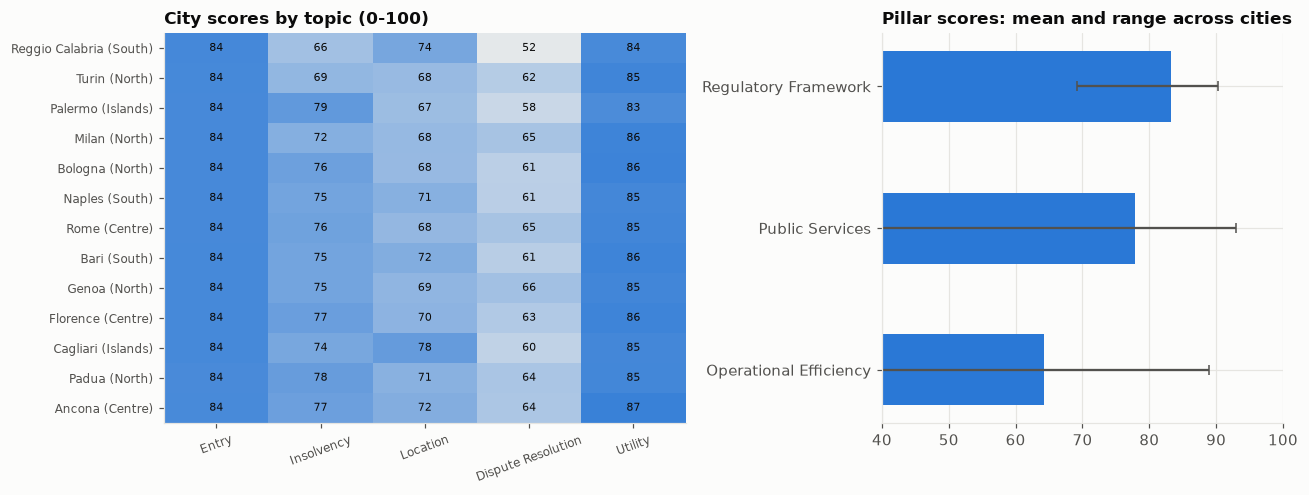

In [6]:
# Italian cities: World Bank Subnational Business Ready 2025 (13 cities; five topics; scores 0-100)
br = pd.read_parquet(PROCESSED / "italy_bready_cities.parquet")
t = br[br.level == "topic"].pivot(index="city", columns="topic", values="score"); t["average"] = t.mean(axis=1); t = t.sort_values("average")
area = br[["city", "area"]].drop_duplicates().set_index("city").area
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
vals = t.drop(columns="average")
axes[0].imshow(vals.values, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("s", ["#f0efec", "#2a78d6"]), vmin=50, vmax=90, aspect="auto"); axes[0].grid(False)
axes[0].set_xticks(range(5), [c.replace("Business ", "").replace(" Services", "") for c in vals.columns], rotation=20, fontsize=8); axes[0].set_yticks(range(len(t)), [f"{c} ({area[c]})" for c in t.index], fontsize=8)
for i in range(vals.shape[0]):
    for j in range(5): axes[0].text(j, i, f"{vals.values[i, j]:.0f}", ha="center", va="center", fontsize=7, color=INK)
axes[0].set_title("City scores by topic (0-100)")
pl = br[br.level == "pillar"].groupby("item").score.agg(["mean", "min", "max"]).loc[["Regulatory Framework", "Public Services", "Operational Efficiency"]]
axes[1].barh(range(3), pl["mean"], color=ITALY_C, height=0.5); axes[1].errorbar(pl["mean"], range(3), xerr=[pl["mean"] - pl["min"], pl["max"] - pl["mean"]], fmt="none", ecolor=INK2, capsize=3)
axes[1].set_yticks(range(3), pl.index); axes[1].invert_yaxis(); axes[1].set_xlim(40, 100); axes[1].set_title("Pillar scores: mean and range across cities"); fig.tight_layout(); save(fig, "09_bready_cities")
display(t.round(1)); print("average by macro-area:", br[br.level == "topic"].groupby("area").score.mean().round(1).to_dict()); print("pillar means:", pl["mean"].round(1).to_dict())

Italy: 95.7% of EUR 64.4bn programmed | median of others 110.7% | rank among 26 (1 = lowest): 4 | countries above 100%: 21


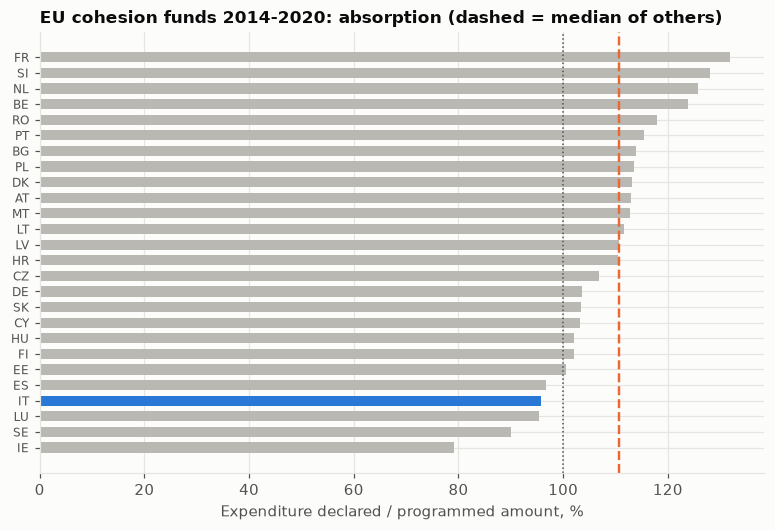

In [7]:
# EU cohesion funds 2014-2020 (ERDF, ESF, Cohesion Fund, YEI): spending declared vs programmed, by member state
ab = pd.read_parquet(PROCESSED / "esif_absorption.parquet"); ab = ab[ab.fund.isin(["ERDF", "ESF", "CF", "YEI"])]
from cifresignificative.core.countries import EU27 as EU27_GEO
ab = ab[ab.geo.isin(EU27_GEO)].groupby("geo")[["planned", "spent"]].sum(); ab["absorption"] = ab.spent / ab.planned * 100; ab = ab.sort_values("absorption")
fig, ax = plt.subplots(figsize=(8.5, 5.2)); cols = [ITALY_C if g == "IT" else PEER_C for g in ab.index]
ax.barh(range(len(ab)), ab.absorption, color=cols, height=0.65); ax.axvline(100, color=INK2, lw=1, ls=":"); ax.axvline(ab.drop("IT").absorption.median(), color=EU_C, lw=1.6, ls="--")
ax.set_yticks(range(len(ab)), [f"{g}" for g in ab.index], fontsize=8); ax.set_xlabel("Expenditure declared / programmed amount, %"); ax.set_title("EU cohesion funds 2014-2020: absorption (dashed = median of others)"); save(fig, "09_esif_absorption")
print("Italy: %.1f%% of EUR %.1fbn programmed | median of others %.1f%% | rank among %d (1 = lowest): %d | countries above 100%%: %d" % (ab.loc["IT", "absorption"], ab.loc["IT", "planned"] / 1e9, ab.drop("IT").absorption.median(), len(ab), list(ab.index).index("IT") + 1, int((ab.absorption > 100).sum())))

Non-observed economy: 11.8% of GDP in 2011, peak 12.5% in 2014, 10.2% in 2023 (EUR 218bn)


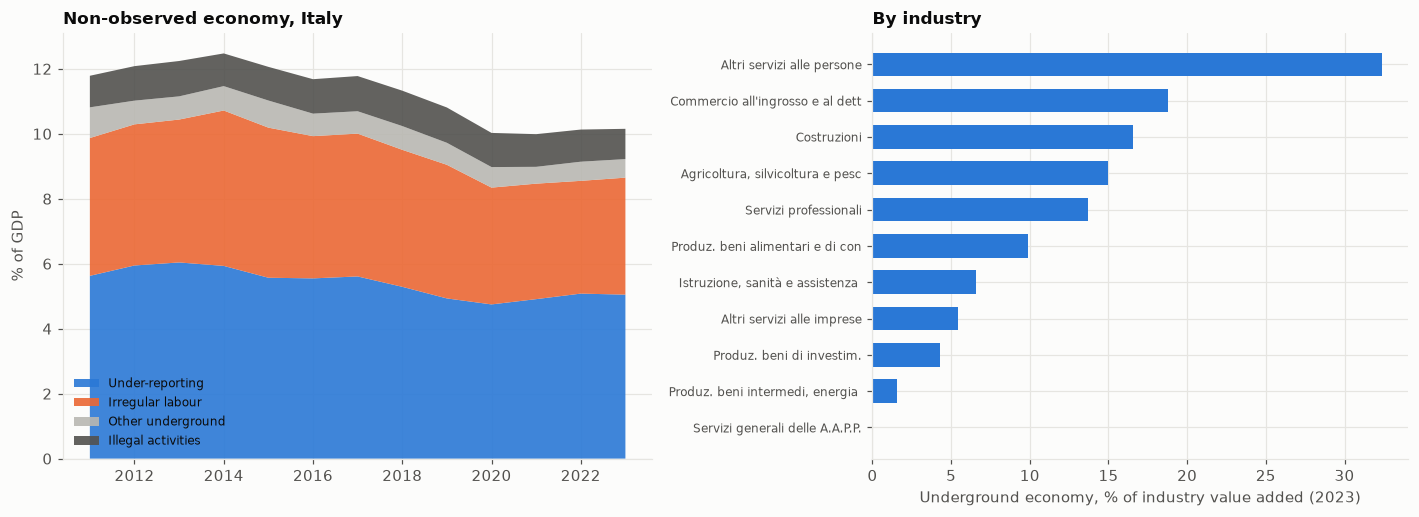

In [8]:
# Italy only: Istat non-observed economy (underground + illegal), % of GDP, and underground share of value added by industry
from cifresignificative.core.sources import istat_unobserved
nz = istat_unobserved.load_components().pivot(index="year", columns="component", values="pct_gdp")
ind = istat_unobserved.load_by_industry(); ind = ind[(ind.component == "underground") & (ind.year == 2023)].set_index("industry").pct_value_added.drop("Totale").sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]; ax.stackplot(nz.index, nz.underreporting, nz.irregular_labour, nz.other_underground, nz.illegal, colors=[ITALY_C, EU_C, PEER_C, INK2], labels=["Under-reporting", "Irregular labour", "Other underground", "Illegal activities"], alpha=0.9)
ax.set_ylabel("% of GDP"); ax.set_title("Non-observed economy, Italy"); ax.legend(loc="lower left", fontsize=8, frameon=False)
ax = axes[1]; ax.barh(range(len(ind)), ind.values, color=ITALY_C, height=0.65); ax.set_yticks(range(len(ind)), [i[:32] for i in ind.index], fontsize=8); ax.set_xlabel("Underground economy, % of industry value added (2023)"); ax.set_title("By industry")
fig.tight_layout(); save(fig, "09_istat_unobserved")
print("Non-observed economy: %.1f%% of GDP in 2011, peak %.1f%% in %d, %.1f%% in 2023 (EUR %.0fbn)" % (nz.non_observed_total[2011], nz.non_observed_total.max(), nz.non_observed_total.idxmax(), nz.non_observed_total[2023], istat_unobserved.load_components().query("component == 'non_observed_total' and year == 2023").meur.iloc[0] / 1000))

## Italy-only evidence from primary sources (not comparable with the EU VAT-gap series)
- **Ministry of Economy and Finance, 2025 report on evasion** (tables I.1, I.4, I.5; upper estimates): the gap in tax revenue was EUR 95.6bn in 2018 and EUR 90.9bn in 2022 (nominal), or 19.7% and 17.0% of tax due (20.1% to 17.2% excluding IMU and excise duties; the report notes this is a third of the 2004 peak of 38.3% and 11.7% below 2019). Including social contributions the gap was EUR 108.4bn (2018) and EUR 102.5bn (2022); the contributions part fell from EUR 12.8bn to 11.6bn.
- **By tax (2022):** self-employed and business income tax (IRPEF) EUR 37.0bn, a propensity of 59.8% (60.2% in 2018); VAT EUR 29.0bn, 18.4% of VAT due (23.4% in 2018; the ministry's method differs from the Commission's 15.0% in 2023); IRES EUR 10.3bn; IRAP EUR 3.6bn. The recent decline is concentrated in VAT, IRAP and IRES, not in self-employed income tax.
- **Istat irregular-employment rate** (share of work performed outside regulation, latest edition): 10.8% in 2005 and 10.0% in 2023; the code for the 'total' status is inferred (see docs/data_dictionary.md).
- **Business environment in 13 Italian cities (World Bank Subnational Business Ready 2025, five topics):** averages run from 72.1 (Reggio Calabria) to 76.6 (Ancona) with no North-South gradient (North 75.1, Centre 76.0, South 74.3, Islands 75.1). The weak spots are the same everywhere: dispute resolution (52.5 in Reggio Calabria to 65.7 in Genoa) and, by pillar, operational efficiency (mean 64.2, against 77.9 for public services and 83.3 for the regulatory framework): the rules are largely national and uniform; what differs and what lags is how they work in practice. Business entry scores about 84 in every city.
- **EU cohesion funds (2014-2020 ERDF, ESF, Cohesion Fund, YEI):** Italy declared 95.7% of the EUR 64.4bn programmed, the 4th lowest of the EU27 (Ireland 79.2%, Sweden 90.0%, Luxembourg 95.3%; median of the others 110.6%); 21 of 26 countries are above 100% because programmes were over-committed. This measures spending against programming at the final reporting date, not the quality of projects or timeliness (the data do not show delays within the period). Late-payment times of public administrations are not covered (no harmonised official series found).
- **Istat non-observed economy (2025 release, years 2011-2023):** the press figure is confirmed: 10.1% of GDP in 2022 (EUR 202bn) and 10.2% in 2023 (EUR 218bn), made of underground economy 9.2% (under-reporting 5.0%, irregular labour 3.6%, other 0.6%) and illegal activities 0.9%. The peak was 12.5% in 2014; the level fell to 9.0% for the underground part in 2020 and has not declined further since. Relative to value added the underground economy is largest in other personal services (32.4%), trade, transport, accommodation and food (18.8%) and construction (16.5%).

## Takeaways
- **Governance scores sit below the northern peers and near the southern ones.** In 2024 Italy scores 69 on government effectiveness (2005: 61; median of the other members 75), 59 on control of corruption (unchanged since 2005; Germany 84, France 73, Spain 63), 67 on regulatory quality (2005: 72) and 68 on rule of law. These are perception-based composites, recalculated under the World Bank's 2025 methodology.
- **VAT compliance gap:** Italy's fell from 27.6% of VAT due in 2013 to 15.0% in 2023, the 5th highest of 26 countries with data, versus an 8.0% median (Germany 9.7%, France 5.6%, Spain 7.6%, Romania 30.0%). The improvement coincides with electronic invoicing, but this series does not prove the cause.
- Across the EU27 the VAT gap is only moderately related to control of corruption (correlation -0.35 in 2023), and government effectiveness tracks income closely (0.80, driven partly by Luxembourg and Ireland). These are cross-sections, not causal tests.
- **Public procurement (2021-2024):** Italy's share of single-bidder contracts was 34% in 2024 against a 27% median of the other members (10th highest of 26; 37% in 2022-23); direct awards are low (3% vs 5%), but decisions take 123 days vs a 74-day median (4th slowest of 27; 172 days in 2023).
- **Not yet available:** a harmonised income/corporate tax gap and any direct measure of spending waste.